# team

Diana

Nimra

Albert

Ahmad

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving survey.csv to survey.csv


# Load the survey dataset

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('survey.csv')

# Inspect its structure, data types, missing values and duplicate records

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   survey_id           11 non-null     object 
 1   community           11 non-null     object 
 2   households          11 non-null     object 
 3   days_without_water  10 non-null     float64
 4   latitude            11 non-null     float64
 5   longitude           11 non-null     float64
dtypes: float64(3), object(3)
memory usage: 660.0+ bytes


In [ ]:
df.head()

,survey_id,community,households,days_without_water,latitude,longitude
0,S01,Community A,10,2.0,35.1,37.1
1,S02,Community A,20,4.0,35.1,37.1
2,S03,Community B,20,5.0,35.4,38.2
3,S04,Community B,10,3.0,35.4,38.2
4,S05,Community C,10,0.0,36.1,38.5


In [ ]:
df.head(20)

,survey_id,community,households,days_without_water,latitude,longitude
0,S01,Community A,10,2.0,35.1,37.1
1,S02,Community A,20,4.0,35.1,37.1
2,S03,Community B,20,5.0,35.4,38.2
3,S04,Community B,10,3.0,35.4,38.2
4,S05,Community C,10,0.0,36.1,38.5
5,S06,Community C,10,1.0,36.1,38.5
6,S07,Community D,20,6.0,36.4,40.1
7,S08,Community D,10,5.0,36.4,40.1
8,S03,Community B,20,5.0,35.4,38.2
9,S09,Community B,unknown,8.0,35.4,38.2


In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
5,False
6,False
7,False
8,True
9,False


# Apply these rules

## Keep one record per survey_id

In [ ]:
df = df.drop_duplicates()
df['survey_id'].duplicated().sum()

np.int64(0)

## Convert households and days_without_water to numeric values

In [ ]:
df['households'] = pd.to_numeric(df['households'], errors='coerce')
df['days_without_water'] = pd.to_numeric(df['days_without_water'], errors='coerce')

In [ ]:
df.head(20)

,survey_id,community,households,days_without_water,latitude,longitude
0,S01,Community A,10.0,2.0,35.1,37.1
1,S02,Community A,20.0,4.0,35.1,37.1
2,S03,Community B,20.0,5.0,35.4,38.2
3,S04,Community B,10.0,3.0,35.4,38.2
4,S05,Community C,10.0,0.0,36.1,38.5
5,S06,Community C,10.0,1.0,36.1,38.5
6,S07,Community D,20.0,6.0,36.4,40.1
7,S08,Community D,10.0,5.0,36.4,40.1
9,S09,Community B,NaN,8.0,35.4,38.2
10,S10,Community C,10.0,NaN,36.1,38.5


In [ ]:
medina_households = df['households'].median()
df['households'] = df['households'].fillna(medina_households)

medina_days_without_water = df['days_without_water'].median()
df['days_without_water'] = df['days_without_water'].fillna(medina_days_without_water)

In [ ]:
df.head(20)

,survey_id,community,households,days_without_water,latitude,longitude
0,S01,Community A,10.0,2.0,35.1,37.1
1,S02,Community A,20.0,4.0,35.1,37.1
2,S03,Community B,20.0,5.0,35.4,38.2
3,S04,Community B,10.0,3.0,35.4,38.2
4,S05,Community C,10.0,0.0,36.1,38.5
5,S06,Community C,10.0,1.0,36.1,38.5
6,S07,Community D,20.0,6.0,36.4,40.1
7,S08,Community D,10.0,5.0,36.4,40.1
9,S09,Community B,10.0,8.0,35.4,38.2
10,S10,Community C,10.0,4.0,36.1,38.5


## Households must be positive whole numbers

In [ ]:
df['households'] = df['households'].apply(lambda x: np.round(x))

In [ ]:
df.head(20)

,survey_id,community,households,days_without_water,latitude,longitude
0,S01,Community A,10.0,2.0,35.1,37.1
1,S02,Community A,20.0,4.0,35.1,37.1
2,S03,Community B,20.0,5.0,35.4,38.2
3,S04,Community B,10.0,3.0,35.4,38.2
4,S05,Community C,10.0,0.0,36.1,38.5
5,S06,Community C,10.0,1.0,36.1,38.5
6,S07,Community D,20.0,6.0,36.4,40.1
7,S08,Community D,10.0,5.0,36.4,40.1
9,S09,Community B,10.0,8.0,35.4,38.2
10,S10,Community C,10.0,4.0,36.1,38.5


## Days without water must be whole numbers between 0 and 7.

In [ ]:
df['days_without_water'] = df['days_without_water'].apply(lambda x: 0 if x < 0 else x)
df['days_without_water'] = df['days_without_water'].apply(lambda x: 7 if x > 7 else x)

In [ ]:
df.head(20)

,survey_id,community,households,days_without_water,latitude,longitude
0,S01,Community A,10.0,2.0,35.1,37.1
1,S02,Community A,20.0,4.0,35.1,37.1
2,S03,Community B,20.0,5.0,35.4,38.2
3,S04,Community B,10.0,3.0,35.4,38.2
4,S05,Community C,10.0,0.0,36.1,38.5
5,S06,Community C,10.0,1.0,36.1,38.5
6,S07,Community D,20.0,6.0,36.4,40.1
7,S08,Community D,10.0,5.0,36.4,40.1
9,S09,Community B,10.0,7.0,35.4,38.2
10,S10,Community C,10.0,4.0,36.1,38.5


## Exclude incomplete or invalid records from the analysis, but retain them in a

In [ ]:
df_clean = df.dropna()

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10 entries, 0 to 10
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   survey_id           10 non-null     object 
 1   community           10 non-null     object 
 2   households          10 non-null     float64
 3   days_without_water  10 non-null     float64
 4   latitude            10 non-null     float64
 5   longitude           10 non-null     float64
dtypes: float64(4), object(2)
memory usage: 560.0+ bytes


# For each community, calculate

## Total households represented

In [ ]:
community_summary = df_clean.groupby('community').agg(
    total_households=('households', 'sum'),
    affected_households=('days_without_water', 'sum')
).reset_index()
community_summary

,community,total_households,affected_households
0,Community A,30.0,6.0
1,Community B,40.0,15.0
2,Community C,30.0,5.0
3,Community D,30.0,11.0


## Households reporting at least three days without water

In [ ]:
df_clean['affected'] = df_clean['days_without_water'] >= 3

summary = df_clean.groupby('community').apply(
    lambda g: pd.Series({
        'total_households': g['households'].sum(),
        'affected_households': g.loc[g['affected'], 'households'].sum()
    })
).reset_index()

summary

/tmp/ipykernel_1360/160011597.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = df_clean.groupby('community').apply(


,community,total_households,affected_households
0,Community A,30.0,20.0
1,Community B,40.0,40.0
2,Community C,30.0,10.0
3,Community D,30.0,30.0


## Percentage of represented households meeting that condition.

In [ ]:
summary['pct_affected'] = (
    summary['affected_households'] / summary['total_households'] * 100
).round(1)

avg_days = df_clean.groupby('community')['days_without_water'].mean().round(2)
summary = summary.merge(avg_days.rename('avg_days_without_water'), on='community')

summary = summary.sort_values('pct_affected', ascending=False).reset_index(drop=True)
summary

,community,total_households,affected_households,pct_affected,avg_days_without_water_x,avg_days_without_water_y
0,Community B,40.0,40.0,100.0,5.00,5.00
1,Community D,30.0,30.0,100.0,5.50,5.50
2,Community A,30.0,20.0,66.7,3.00,3.00
3,Community C,30.0,10.0,33.3,1.67,1.67


## Produce a bar chart comparing those percentages

In [ ]:
import matplotlib.pyplot as plt

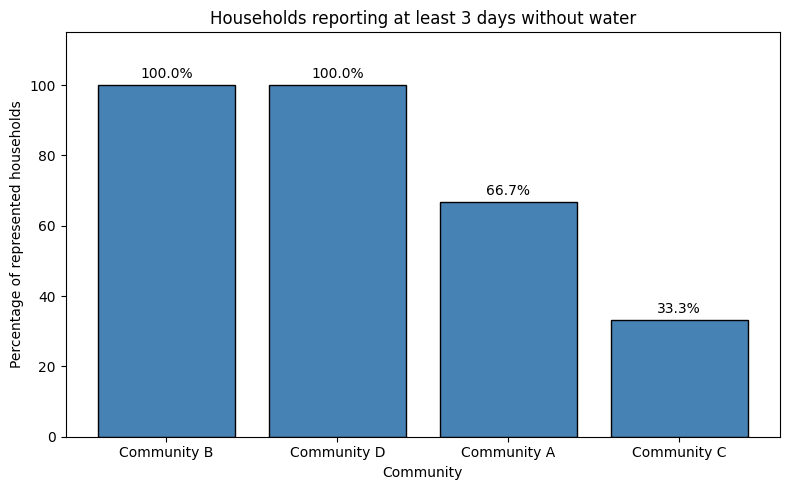

In [ ]:
plt.figure(figsize=(8, 5))
bars = plt.bar(
    summary['community'],
    summary['pct_affected'],
    color='steelblue',
    edgecolor='black'
)
plt.ylabel('Percentage of represented households')
plt.xlabel('Community')
plt.title('Households reporting at least 3 days without water')
plt.ylim(0, 115)

for bar, val in zip(bars, summary['pct_affected']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        val + 2,
        f'{val}%',
        ha='center',
        fontsize=10
    )

plt.tight_layout()
plt.show()

## Recommend which community to investigate first, explaining your reasoning

Investigate Community D first.

Investigate Community B second.

Reason: Community D and Community B are tied at 100% of represented households reporting at least 3 days without water, and both represent 30 households.

Tie-breaker: severity. Community D has an average of 5.5 days without water, compared with Community B's 4.0 days.

Community A (66.7%) is a secondary concern.

Community C (0%) needs no urgent follow-up.